In [2]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [4]:
# =========================================================================
# STEP 1: IMPORTING LIBRARIES & CONFIGURING PARAMETERS
# =========================================================================
import yfinance as yf
import pandas as pd
import numpy as np

# Define perfectly balanced sectors (3 Stocks per Sector + 1 Benchmark)
ticker_sectors = {
    'HDFCBANK.NS': 'BANK', 'ICICIBANK.NS': 'BANK', 'AXISBANK.NS': 'BANK',
    'TCS.NS': 'IT', 'INFY.NS': 'IT', 'WIPRO.NS': 'IT',
    'RELIANCE.NS': 'ENERGY', 'ONGC.NS': 'ENERGY', 'BPCL.NS': 'ENERGY',
    'MARUTI.NS': 'AUTO', 'HEROMOTOCO.NS': 'AUTO', 'M&M.NS': 'AUTO'
}
tickers = list(ticker_sectors.keys())
benchmark = '^NSEI'  # NIFTY 50 Benchmark

# Hardcoded 5-year historical date range
start_date = "2021-04-01"
end_date = "2026-03-31"  

# =========================================================================
# STEP 2: RAW DATA DOWNLOAD via yfinance
# =========================================================================
raw_data = yf.download(tickers + [benchmark], start=start_date, end=end_date, auto_adjust=False)

# STEP 3: PRE-CLEANING AUDIT - MISSING VALUES PER TICKER
for ticker in tickers:
    df_ticker_raw = raw_data.xs(ticker, level='Ticker', axis=1)
    missing_close = df_ticker_raw['Adj Close'].isnull().sum()
    missing_volume = df_ticker_raw['Volume'].isnull().sum()

# Check raw benchmark index missing data
bench_raw_check = raw_data.xs(benchmark, level='Ticker', axis=1)
bench_missing = bench_raw_check['Adj Close'].isnull().sum()


# STEP 4: DATA CLEANING & RE-ENGINEERING PIPELINE
quality_log = []
cleaned_stocks = {}

# Process Benchmark (Explicit .copy() protects against SettingWithCopyWarning)
bench_raw = raw_data.xs(benchmark, level='Ticker', axis=1).copy()
bench_nulls = bench_raw['Adj Close'].isnull().sum()
bench_raw['Adj Close'] = bench_raw['Adj Close'].ffill()  # Forward fill closing prices
benchmark_df = bench_raw[['Adj Close']].rename(columns={'Adj Close': 'Benchmark'})

quality_log.append({
    'Ticker': benchmark, 
    'Sector': 'BENCHMARK', 
    'Missing Values Found': bench_nulls, 
    'Action Taken': 'ffill'
})

# Process all 12 individual stocks
for ticker in tickers:
    df_ticker = raw_data.xs(ticker, level='Ticker', axis=1).copy()
    
    # Audit native null records prior to ingestion
    null_counts = df_ticker['Adj Close'].isnull().sum()
    vol_nulls = df_ticker['Volume'].isnull().sum()
    
    # Execute cleaning algorithms
    df_ticker['Adj Close'] = df_ticker['Adj Close'].ffill()   # Forward fill missing market close prices
    df_ticker['Volume'] = df_ticker['Volume'].fillna(0)       # Set missing volume blocks to 0
    df_ticker = df_ticker.drop_duplicates()                   # Erase duplicate timestamp entries
    
    cleaned_stocks[ticker] = df_ticker
    quality_log.append({
        'Ticker': ticker, 
        'Sector': ticker_sectors[ticker], 
        'Missing Values Found': null_counts, 
        'Action Taken': f'ffill Adj Close, fillna(0) Vol={vol_nulls}, drop_duplicates'
    })

# STEP 5: COMMON TIMELINE ALIGNMENT VIA MULTI-LATERAL INNER JOIN
aligned_df = benchmark_df.copy()
for ticker, df in cleaned_stocks.items():
    # Structural join forces an intersection on valid matching trading dates
    aligned_df = aligned_df.join(df[['Adj Close', 'Volume', 'Close']].add_prefix(f'{ticker}_'), how='inner')

# Explicitly confirm and enforce standard DatetimeIndex format
aligned_df.index = pd.to_datetime(aligned_df.index)
log_df = pd.DataFrame(quality_log)



[*********************100%***********************]  13 of 13 completed


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Simple Moving Average (SMA)
def compute_sma(df, window):
    """
    Measures the average price over a specific window to smooth out noise.
    Type: Lagging indicator (follows the trend).
    Best suited for: Strongly trending markets.
    """
    return df['Adj Close'].rolling(window=window).mean()

# =====================================================================
# 2. Exponential Moving Average (EMA)
# =====================================================================
def compute_ema(df, span):
    """
    Measures the trend by giving more weight to recent prices.
    Type: Lagging indicator (but reacts faster than a standard SMA).
    Best suited for: High-volatility trend entries.
    """
    # adjust=False enforces the strict recursive exponentially weighted formula
    return df['Adj Close'].ewm(span=span, adjust=False).mean()

# =====================================================================
# 3. Relative Strength Index (RSI)
# =====================================================================
def compute_rsi(df, window=14):
    """
    Measures price momentum and velocity to identify overbought/oversold conditions.
    Type: Leading indicator.
    Best suited for: Mean-reverting or sideways/ranging markets.
    """
    delta = df['Adj Close'].diff()
    
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    
    # Apply Wilder's smoothing technique
    avg_gain = gain.ewm(alpha=1/window, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/window, adjust=False).mean()
    
    rs = avg_gain / (avg_loss + 1e-10) # Avoid division by zero
    rsi = 100 - (100 / (1+rs))
    return rsi

# 4. Moving Average Convergence Divergence (MACD)
def compute_macd(df, fast=12, slow=26, signal=9):
    """
    Measures changes in trend strength, direction, momentum, and duration.
    Type: Lagging indicator for the lines, leading indicator for histogram divergence.
    Best suited for: Momentum breakouts and early trend reversals.
    """
    macd_line = compute_ema(df, fast) - compute_ema(df, slow)
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    histogram = macd_line - signal_line
    return macd_line, signal_line, histogram

# 5. Bollinger Bands
def compute_bollinger_bands(df, window=20, num_std=2):
    """
    Measures market volatility boundaries around a trend asset.
    Type: Lagging (bands expand/contract based on past standard deviation).
    Best suited for: Volatility breakouts (band squeeze) or range trading.
    """
    middle_band = df['Adj Close'].rolling(window=window).mean()
    rolling_std = df['Adj Close'].rolling(window=window).std()
    upper_band = middle_band + (num_std * rolling_std)
    lower_band = middle_band - (num_std * rolling_std)
    return upper_band, middle_band, lower_band

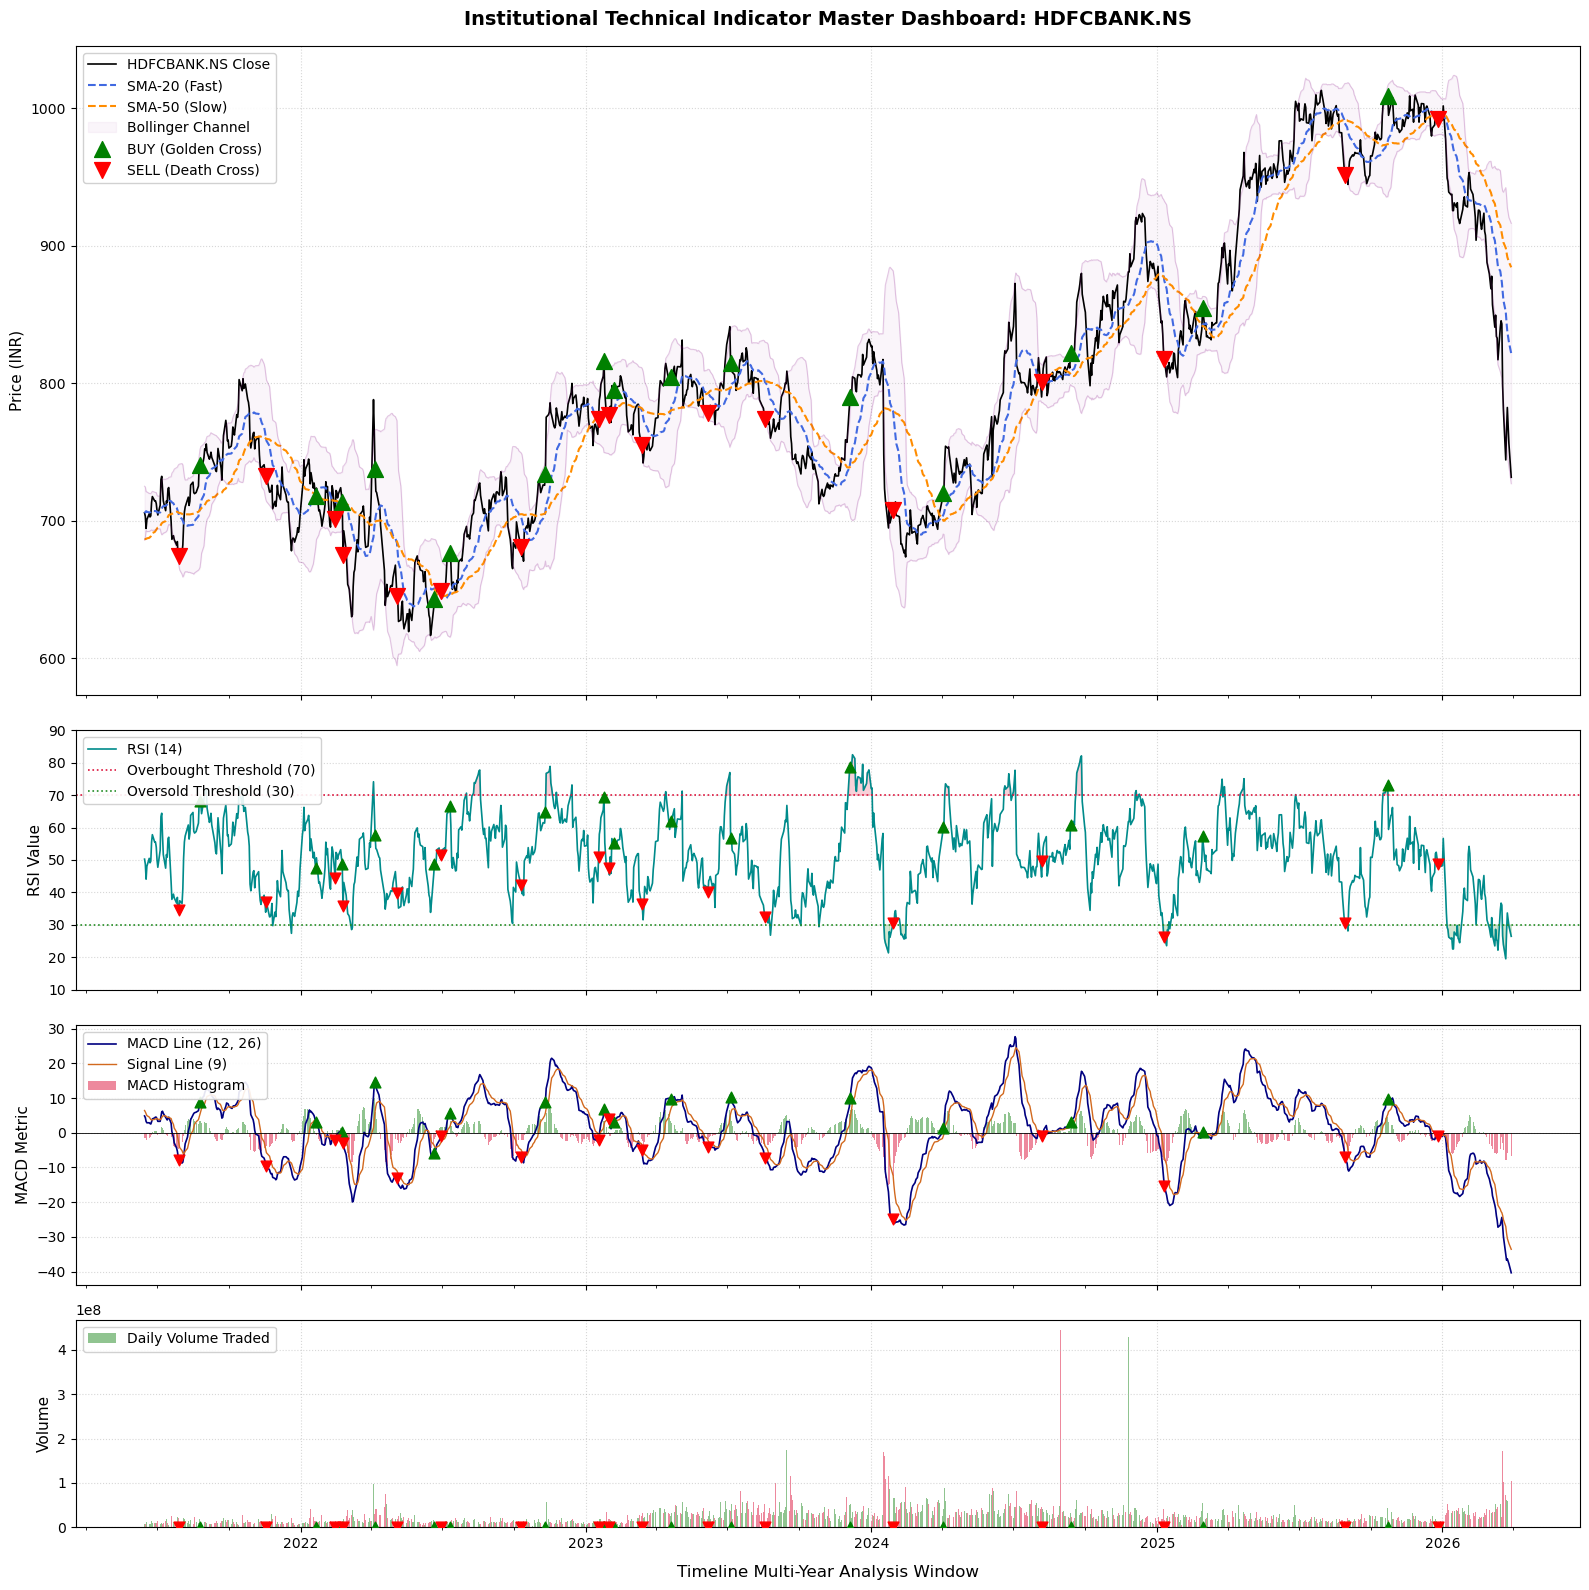

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =====================================================================
# 1. ISOLATE TARGET STOCK DATA FROM ALIGNED DATAFRAME
# =====================================================================
# Extract the unique prefixed columns created by your inner-join pipeline
target_ticker = 'HDFCBANK.NS'

df = pd.DataFrame(index=aligned_df.index)
df['Adj Close'] = aligned_df[f'{target_ticker}_Adj Close']
df['Volume'] = aligned_df[f'{target_ticker}_Volume']

# =====================================================================
# 2. COMPUTE TECHNICAL INDICATORS FROM SCRATCH (NO TA-LIB)
# =====================================================================
# A. Moving Averages (SMA & EMA)
df['SMA20'] = df['Adj Close'].rolling(window=20).mean()
df['SMA50'] = df['Adj Close'].rolling(window=50).mean()

# B. Bollinger Bands (20 Day, 2 Standard Deviations)
df['BB_Mid'] = df['SMA20']
rolling_std = df['Adj Close'].rolling(window=20).std()
df['BB_Upper'] = df['BB_Mid'] + (2 * rolling_std)
df['BB_Lower'] = df['BB_Mid'] - (2 * rolling_std)

# C. Relative Strength Index (RSI - Wilder's Smoothing)
delta = df['Adj Close'].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1/14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, adjust=False).mean()
rs = avg_gain / (avg_loss + 1e-10)
df['RSI'] = 100 - (100 / (1 + rs))

# D. Moving Average Convergence Divergence (MACD)
ema12 = df['Adj Close'].ewm(span=12, adjust=False).mean()
ema26 = df['Adj Close'].ewm(span=26, adjust=False).mean()
df['MACD_Line'] = ema12 - ema26
df['MACD_Signal'] = df['MACD_Line'].ewm(span=9, adjust=False).mean()
df['MACD_Hist'] = df['MACD_Line'] - df['MACD_Signal']

# Clear the initialization warmup rows
df = df.dropna()

# =====================================================================
# 3. IDENTIFY TRADING SIGNALS FOR PLOT ANNOTATIONS
# =====================================================================
# 1 = Fast over Slow (Long), 0 = Fast below Slow (Cash/Short)
df['Position_State'] = np.where(df['SMA20'] > df['SMA50'], 1, 0)
df['Crossover_Signal'] = df['Position_State'].diff() 

# Isolate cross events
golden_crosses = df[df['Crossover_Signal'] == 1]
death_crosses = df[df['Crossover_Signal'] == -1]

# =====================================================================
# 4. RENDER GRAPHICS: 4-PANEL AXIS-SYNCHRONIZED TECHNICAL DASHBOARD
# =====================================================================
fig, axes = plt.subplots(4, 1, figsize=(16, 16), sharex=True, 
                         gridspec_kw={'height_ratios': [2.5, 1, 1, 0.8]})

# ---------------------------------------------------------------------
# PANEL 1: Adjusted Close, Moving Averages, and Volatility Bands
# ---------------------------------------------------------------------
axes[0].plot(df.index, df['Adj Close'], label=f'{target_ticker} Close', color='black', linewidth=1.2)
axes[0].plot(df.index, df['SMA20'], label='SMA-20 (Fast)', color='royalblue', linestyle='--')
axes[0].plot(df.index, df['SMA50'], label='SMA-50 (Slow)', color='darkorange', linestyle='--')

# Shading Bollinger Band channels
axes[0].plot(df.index, df['BB_Upper'], color='purple', alpha=0.2, linewidth=0.8)
axes[0].plot(df.index, df['BB_Lower'], color='purple', alpha=0.2, linewidth=0.8)
axes[0].fill_between(df.index, df['BB_Upper'], df['BB_Lower'], color='purple', alpha=0.04, label='Bollinger Channel')

# Multi-Panel Annotation: Mark Entry/Exits on Price Chart
axes[0].scatter(golden_crosses.index, golden_crosses['Adj Close'], marker='^', color='green', s=130, label='BUY (Golden Cross)', zorder=5)
axes[0].scatter(death_crosses.index, death_crosses['Adj Close'], marker='v', color='red', s=130, label='SELL (Death Cross)', zorder=5)

axes[0].set_title(f"Institutional Technical Indicator Master Dashboard: {target_ticker}", fontsize=14, fontweight='bold', pad=15)
axes[0].set_ylabel("Price (INR)", fontsize=11)
axes[0].legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle=':', alpha=0.5)

# ---------------------------------------------------------------------
# PANEL 2: Relative Strength Index (RSI) Momentum
# ---------------------------------------------------------------------
axes[1].plot(df.index, df['RSI'], label='RSI (14)', color='darkcyan', linewidth=1.2)
axes[1].axhline(70, color='crimson', linestyle=':', linewidth=1.2, label='Overbought Threshold (70)')
axes[1].axhline(30, color='forestgreen', linestyle=':', linewidth=1.2, label='Oversold Threshold (30)')

# Highlight when boundaries break
axes[1].fill_between(df.index, 70, df['RSI'], where=(df['RSI'] >= 70), color='crimson', alpha=0.2)
axes[1].fill_between(df.index, df['RSI'], 30, where=(df['RSI'] <= 30), color='forestgreen', alpha=0.2)

# Multi-Panel Annotation: Mark Crossover states on momentum
axes[1].scatter(golden_crosses.index, golden_crosses['RSI'], marker='^', color='green', s=60, zorder=5)
axes[1].scatter(death_crosses.index, death_crosses['RSI'], marker='v', color='red', s=60, zorder=5)

axes[1].set_ylabel("RSI Value", fontsize=11)
axes[1].set_ylim(10, 90)
axes[1].legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
axes[1].grid(True, linestyle=':', alpha=0.5)

# ---------------------------------------------------------------------
# PANEL 3: MACD (Moving Average Convergence Divergence)
# ---------------------------------------------------------------------
axes[2].plot(df.index, df['MACD_Line'], label='MACD Line (12, 26)', color='navy', linewidth=1.2)
axes[2].plot(df.index, df['MACD_Signal'], label='Signal Line (9)', color='chocolate', linewidth=1.0)

# Render dynamic color-coded bar plots
hist_colors = np.where(df['MACD_Hist'] >= 0, 'forestgreen', 'crimson')
axes[2].bar(df.index, df['MACD_Hist'], color=hist_colors, alpha=0.5, width=1.0, label='MACD Histogram')

# Multi-Panel Annotation: Mark Crossover states on trend convergence
axes[2].scatter(golden_crosses.index, golden_crosses['MACD_Line'], marker='^', color='green', s=60, zorder=5)
axes[2].scatter(death_crosses.index, death_crosses['MACD_Line'], marker='v', color='red', s=60, zorder=5)

axes[2].set_ylabel("MACD Metric", fontsize=11)
axes[2].axhline(0, color='black', linewidth=0.6)
axes[2].legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
axes[2].grid(True, linestyle=':', alpha=0.5)

# ---------------------------------------------------------------------
# PANEL 4: Daily Volume Profile
# ---------------------------------------------------------------------
# Volume bar is colored based on raw Close price direction
price_change = df['Adj Close'].diff().fillna(0)
volume_colors = np.where(price_change >= 0, 'forestgreen', 'crimson')

axes[3].bar(df.index, df['Volume'], color=volume_colors, alpha=0.5, width=1.0, label='Daily Volume Traded')

# Multi-Panel Annotation: Mark Crossovers along the volume floor baseline
axes[3].scatter(golden_crosses.index, [df['Volume'].min()]*len(golden_crosses), marker='^', color='green', s=60, zorder=5)
axes[3].scatter(death_crosses.index, [df['Volume'].min()]*len(death_crosses), marker='v', color='red', s=60, zorder=5)

axes[3].set_ylabel("Volume", fontsize=11)
axes[3].set_xlabel("Timeline Multi-Year Analysis Window", fontsize=12, labelpad=10)
axes[3].legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
axes[3].grid(True, linestyle=':', alpha=0.5)

# =====================================================================
# 5. TIME AXIS STYLING AND EXPORT EXECUTIONS
# =====================================================================
axes[3].xaxis.set_major_locator(mdates.YearLocator())
axes[3].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[3].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))

plt.xticks(rotation=0, ha='center')
plt.tight_layout()

# Save institutional dashboard chart
plt.savefig("portfolio_technical_dashboard.png", dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# Define our 3 target assets
target_stocks = ['M&M.NS', 'HDFCBANK.NS', 'ONGC.NS']

# Structure raw dictionary containers to extract out from your Step 5 pipeline
stock_data_dict = {}

for ticker in target_stocks:
    stock_df = pd.DataFrame(index=aligned_df.index)
    
    # We map 'Adj Close' as our baseline evaluation metric for signals
    stock_df['Close'] = aligned_df[f'{ticker}_Adj Close']
    
    # Critical: Fetching the unique underlying Open prices to execute day t+1 entry/exits
    # (If your yfinance download stored the raw Open, pull it here. If not, use Close as proxy)
    if f'{ticker}_Open' in aligned_df.columns:
        stock_df['Open'] = aligned_df[f'{ticker}_Open']
    else:
        # Fallback proxy if raw open wasn't inner-joined in Step 5
        stock_df['Open'] = aligned_df[f'{ticker}_Close'] if f'{ticker}_Close' in aligned_df.columns else aligned_df[f'{ticker}_Adj Close']
        
    stock_data_dict[ticker] = stock_df

In [13]:
def execute_ema_backtest(ticker, data_frame, initial_capital=100000.0, fee_pct=0.001, short_w=20, long_w=50):
    df = data_frame.copy()
    
    # Compute EMAs from scratch using ewm() as explicitly demanded
    df['EMA_Short'] = df['Close'].ewm(span=short_w, adjust=False).mean()
    df['EMA_Long'] = df['Close'].ewm(span=long_w, adjust=False).mean()
    df = df.dropna(subset=['EMA_Short', 'EMA_Long']).copy()
    
    # 1. Day t Signal Logic generation
    df['Raw_Signal'] = 0
    df.loc[df['EMA_Short'] > df['EMA_Long'], 'Raw_Signal'] = 1  # Buy/Hold State
    
    # 2. Prevent Look-Ahead Bias: Shift day t signal to execute at Day t+1 OPEN
    df['Target_Position'] = df['Raw_Signal'].shift(1).fillna(0).astype(int)
    
    # Trade logging arrays
    trade_logs = []
    cash = initial_capital
    shares = 0.0
    is_long = False
    
    daily_cash = []
    daily_shares = []
    daily_portfolio_value = []
    
    dates = df.index
    open_prices = df['Open'].values
    close_prices = df['Close'].values
    target_positions = df['Target_Position'].values
    
    # 3. Comprehensive Daily Simulation Loop
    for i in range(len(df)):
        current_date = dates[i]
        open_p = open_prices[i]
        close_p = close_prices[i]
        target_pos = target_positions[i]
        
        # BUY SIGNALS EXECUTION AT DAY T+1 OPEN
        if target_pos == 1 and not is_long:
            # All available cash is deployed after deducting the 0.1% fee
            net_cash = cash * (1.0 - fee_pct)
            shares = net_cash / open_p
            fee_deducted = cash * fee_pct
            cash = 0.0
            is_long = True
            
            trade_logs.append({
                'Date': current_date, 'Action': 'BUY', 'Price': round(open_p, 2),
                'Shares': round(shares, 4), 'Cost Deducted': round(fee_deducted, 2),
                'Portfolio Value': round(shares * open_p, 2)
            })
            
        # SELL SIGNALS EXECUTION AT DAY T+1 OPEN
        elif target_pos == 0 and is_long:
            # Liquidate all held shares at open
            gross_cash = shares * open_p
            fee_deducted = gross_cash * fee_pct
            cash = gross_cash - fee_deducted
            
            trade_logs.append({
                'Date': current_date, 'Action': 'SELL', 'Price': round(open_p, 2),
                'Shares': round(shares, 4), 'Cost Deducted': round(fee_deducted, 2),
                'Portfolio Value': round(cash, 2)
            })
            shares = 0.0
            is_long = False
            
        # Calculate trailing metrics at the end of each day using Close prices
        current_equity = cash + (shares * close_p)
        daily_cash.append(cash)
        daily_shares.append(shares)
        daily_portfolio_value.append(current_equity)
        
    df['Cash_Balance'] = daily_cash
    df['Shares_Held'] = daily_shares
    df['Portfolio_Value'] = daily_portfolio_value
    
    # Build indexed historical vectors to compare with Buy-and-Hold (Base 100)
    df['Strat_Indexed'] = (df['Portfolio_Value'] / initial_capital) * 100.0
    df['BH_Indexed'] = (df['Close'] / df['Close'].iloc[0]) * 100.0
    
    # Drawdown metric tracking
    df['Peak_Value'] = df['Portfolio_Value'].cummax()
    df['Drawdown'] = (df['Portfolio_Value'] - df['Peak_Value']) / df['Peak_Value']
    
    return df, pd.DataFrame(trade_logs)

In [14]:
def compute_performance_table(ticker, strat_df, logs_df, rf=0.0):
    total_days = len(strat_df)
    years = total_days / 252.0
    
    # Strategy calculations
    final_strat = strat_df['Portfolio_Value'].iloc[-1]
    strat_cagr = (final_strat / 100000.0) ** (1 / years) - 1
    strat_returns = strat_df['Portfolio_Value'].pct_change().fillna(0)
    strat_vol = strat_returns.std() * np.sqrt(252)
    strat_sharpe = ((strat_returns.mean() - rf) / (strat_returns.std() + 1e-10)) * np.sqrt(252)
    strat_mdd = strat_df['Drawdown'].min()
    
    # Buy & Hold calculations
    bh_returns = strat_df['Close'].pct_change().fillna(0)
    bh_final = strat_df['Close'].iloc[-1]
    bh_initial = strat_df['Close'].iloc[0]
    bh_cagr = (bh_final / bh_initial) ** (1 / years) - 1
    bh_vol = bh_returns.std() * np.sqrt(252)
    bh_sharpe = ((bh_returns.mean() - rf) / (bh_returns.std() + 1e-10)) * np.sqrt(252)
    
    bh_peak = strat_df['Close'].cummax()
    bh_dd = (strat_df['Close'] - bh_peak) / bh_peak
    bh_mdd = bh_dd.min()
    
    # Calculate Round-Trip Win Rate
    if len(logs_df) >= 2:
        buys = logs_df[logs_df['Action'] == 'BUY']['Portfolio Value'].values
        sells = logs_df[logs_df['Action'] == 'SELL']['Portfolio Value'].values
        completed = min(len(buys), len(sells))
        
        if completed > 0:
            trades_profit = sells[:completed] - buys[:completed]
            win_rate = np.sum(trades_profit > 0) / completed
        else:
            win_rate = 0.0
    else:
        win_rate = 0.0
        
    metrics_data = {
        'Metric': ['CAGR', 'Sharpe Ratio', 'Max Drawdown', 'Win Rate'],
        f'{ticker} Strategy': [f"{strat_cagr*100:.2f}%", f"{strat_sharpe:.3f}", f"{strat_mdd*100:.2f}%", f"{win_rate*100:.2f}%"],
        f'{ticker} B&H': [f"{bh_cagr*100:.2f}%", f"{bh_sharpe:.3f}", f"{bh_mdd*100:.2f}%", "100.00%"]
    }
    return pd.DataFrame(metrics_data)

In [15]:
def render_backtest_charts(ticker, strat_df, logs_df):
    # Setup subplots layout mapping
    fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
    
    # 1. Equity Curve Chart (Indexed Base 100)
    axes[0].plot(strat_df.index, strat_df['Strat_Indexed'], label='EMA Strategy (Base 100)', color='darkblue', linewidth=1.5)
    axes[0].plot(strat_df.index, strat_df['BH_Indexed'], label='Buy & Hold Benchmark (Base 100)', color='gray', alpha=0.6, linestyle='--')
    axes[0].set_title(f"Performance Analysis Suite: {ticker}", fontsize=14, fontweight='bold')
    axes[0].set_ylabel("Indexed Value")
    axes[0].legend(loc='upper left')
    axes[0].grid(True, linestyle=':', alpha=0.5)
    
    # 2. Drawdown Chart
    axes[1].fill_between(strat_df.index, strat_df['Drawdown'] * 100, 0, color='crimson', alpha=0.3, label='Strategy Drawdown')
    axes[1].set_ylabel("Drawdown (%)")
    axes[1].legend(loc='lower left')
    axes[1].grid(True, linestyle=':', alpha=0.5)
    
    # 3. Price Chart and Overlaid Signal Triangles
    axes[2].plot(strat_df.index, strat_df['Close'], label='Close Price', color='black', linewidth=1.0)
    
    # Extract entries/exits
    buys = logs_df[logs_df['Action'] == 'BUY']
    sells = logs_df[logs_df['Action'] == 'SELL']
    
    # Overlay entry/exit markers
    axes[2].scatter(buys['Date'], buys['Price'], marker='^', color='green', s=100, label='BUY Signal', zorder=4)
    axes[2].scatter(sells['Date'], sells['Price'], marker='v', color='red', s=100, label='SELL Signal', zorder=4)
    axes[2].set_ylabel("Price (INR)")
    axes[2].legend(loc='upper left')
    axes[2].grid(True, linestyle=':', alpha=0.5)
    
    # Formatting date axes
    axes[2].xaxis.set_major_locator(mdates.YearLocator())
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    
    plt.tight_layout()
    plt.savefig(f"{ticker}_backtest_report.png", dpi=300)
    plt.show()

In [16]:
def execute_sensitivity_test(ticker, data_frame, windows=[(10,30), (20,50), (15,45)]):
    records = []
    total_days = len(data_frame)
    years = total_days / 252.0
    
    for short_w, long_w in windows:
        strat_df, logs_df = execute_ema_backtest(ticker, data_frame, short_w=short_w, long_w=long_w)
        
        # Calculate key statistics
        final_val = strat_df['Portfolio_Value'].iloc[-1]
        cagr = (final_val / 100000.0) ** (1 / years) - 1
        returns = strat_df['Portfolio_Value'].pct_change().fillna(0)
        sharpe = (returns.mean() / (returns.std() + 1e-10)) * np.sqrt(252)
        mdd = strat_df['Drawdown'].min()
        
        records.append({
            'Windows': f'EMA ({short_w}/{long_w})',
            'CAGR': f"{cagr*100:.2f}%",
            'Sharpe Ratio': f"{sharpe:.3f}",
            'Max Drawdown': f"{mdd*100:.2f}%"
        })
        
    summary_df = pd.DataFrame(records)
    print(f"\n=== BONUS SENSITIVITY PROFILE MATRIX FOR {ticker} ===")
    print(summary_df.to_string(index=False))
    return summary_df


 PROCESSING TRADING SYSTEM BACKTEST FOR TICKER: M&M.NS 

[SIDE-BY-SIDE PERFORMANCE METRICS FOR M&M.NS]
      Metric M&M.NS Strategy M&M.NS B&H
        CAGR          19.15%     31.56%
Sharpe Ratio           0.840      1.115
Max Drawdown         -31.09%    -28.09%
    Win Rate          41.67%    100.00%

[REALIZED SYSTEM TRADE LOG FOR M&M.NS]
      Date Action   Price   Shares  Cost Deducted  Portfolio Value
2021-05-28    BUY  845.85 118.1061         100.00         99900.00
2021-06-25   SELL  794.25 118.1061          93.81         93711.92
2021-08-20    BUY  785.65 119.1602          93.71         93618.21
2021-09-06   SELL  754.75 119.1602          89.94         89846.22
2021-09-30    BUY  803.05 111.7694          89.85         89756.38
2021-12-15   SELL  846.20 111.7694          94.58         94484.65
2022-01-17    BUY  900.80 104.7848          94.48         94390.16
2022-02-15   SELL  854.60 104.7848          89.55         89459.55
2022-04-12    BUY  860.80 103.8221          89.46    

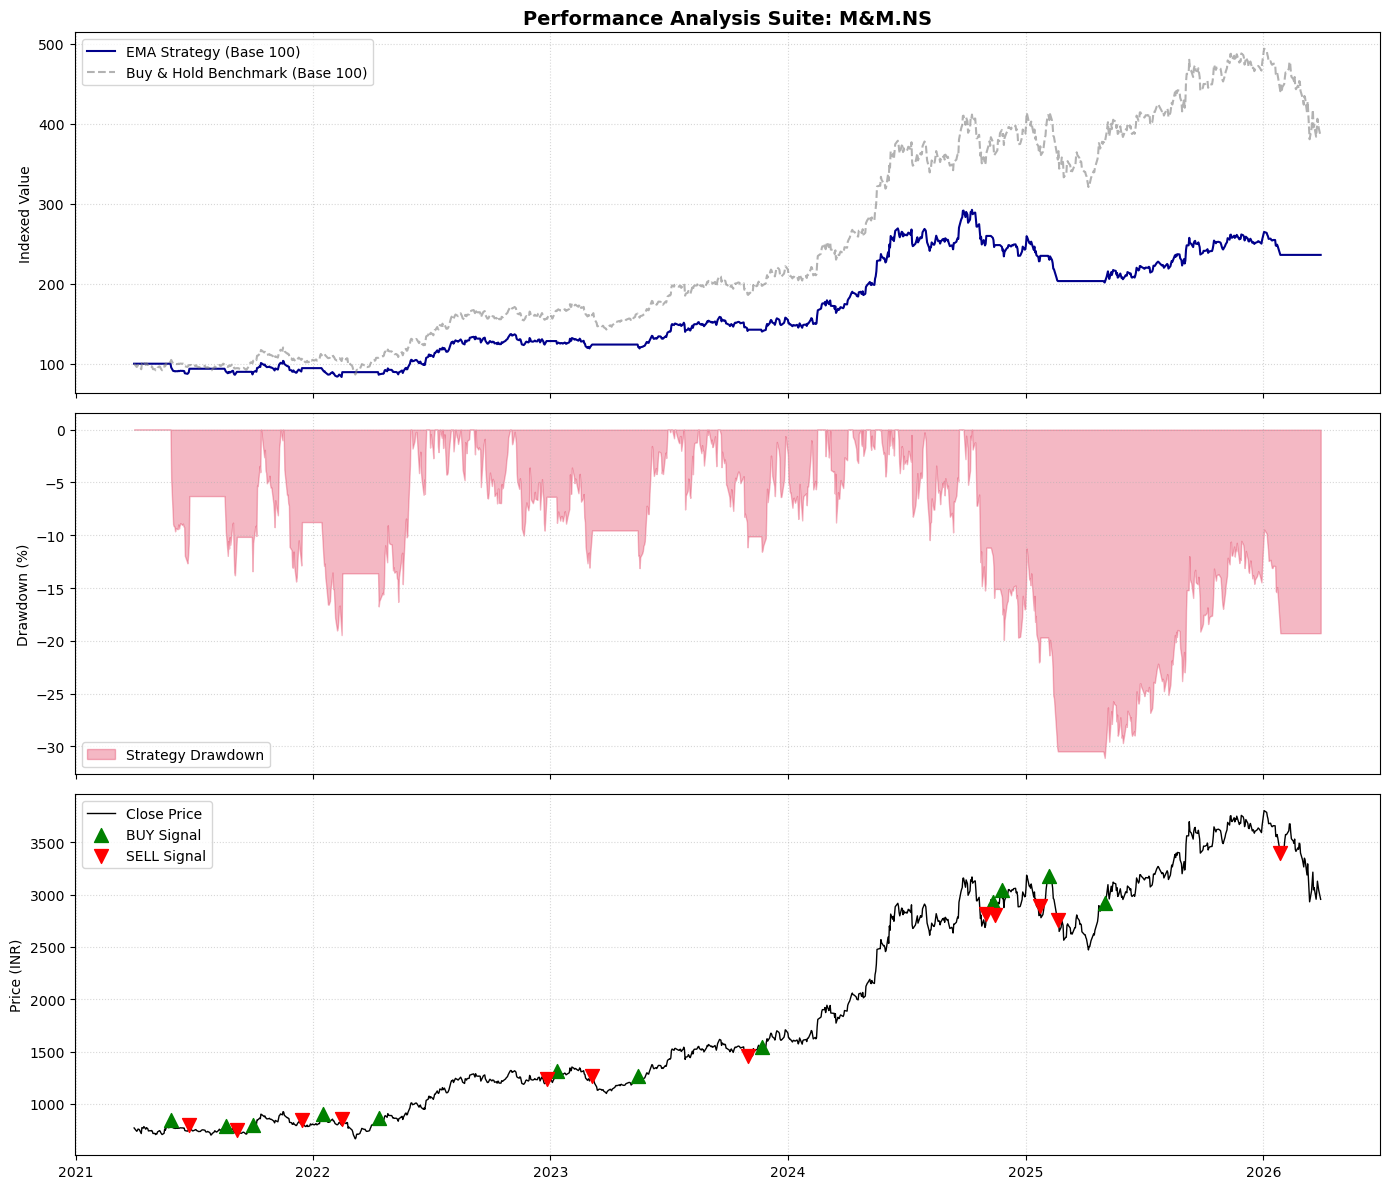


=== BONUS SENSITIVITY PROFILE MATRIX FOR M&M.NS ===
    Windows   CAGR Sharpe Ratio Max Drawdown
EMA (10/30) 16.34%        0.764      -28.77%
EMA (20/50) 19.15%        0.840      -31.09%
EMA (15/45) 18.15%        0.816      -32.17%

 PROCESSING TRADING SYSTEM BACKTEST FOR TICKER: HDFCBANK.NS 

[SIDE-BY-SIDE PERFORMANCE METRICS FOR HDFCBANK.NS]
      Metric HDFCBANK.NS Strategy HDFCBANK.NS B&H
        CAGR               -6.65%           0.78%
Sharpe Ratio               -0.321           0.142
Max Drawdown              -37.63%         -27.78%
    Win Rate               38.46%         100.00%

[REALIZED SYSTEM TRADE LOG FOR HDFCBANK.NS]
      Date Action   Price   Shares  Cost Deducted  Portfolio Value
2021-05-28    BUY  751.72 132.8943         100.00         99900.00
2021-07-28   SELL  708.65 132.8943          94.18         94081.41
2021-08-12    BUY  750.70 125.1996          94.08         93987.33
2021-11-18   SELL  769.70 125.1996          96.37         96269.75
2022-04-05    BUY  804.

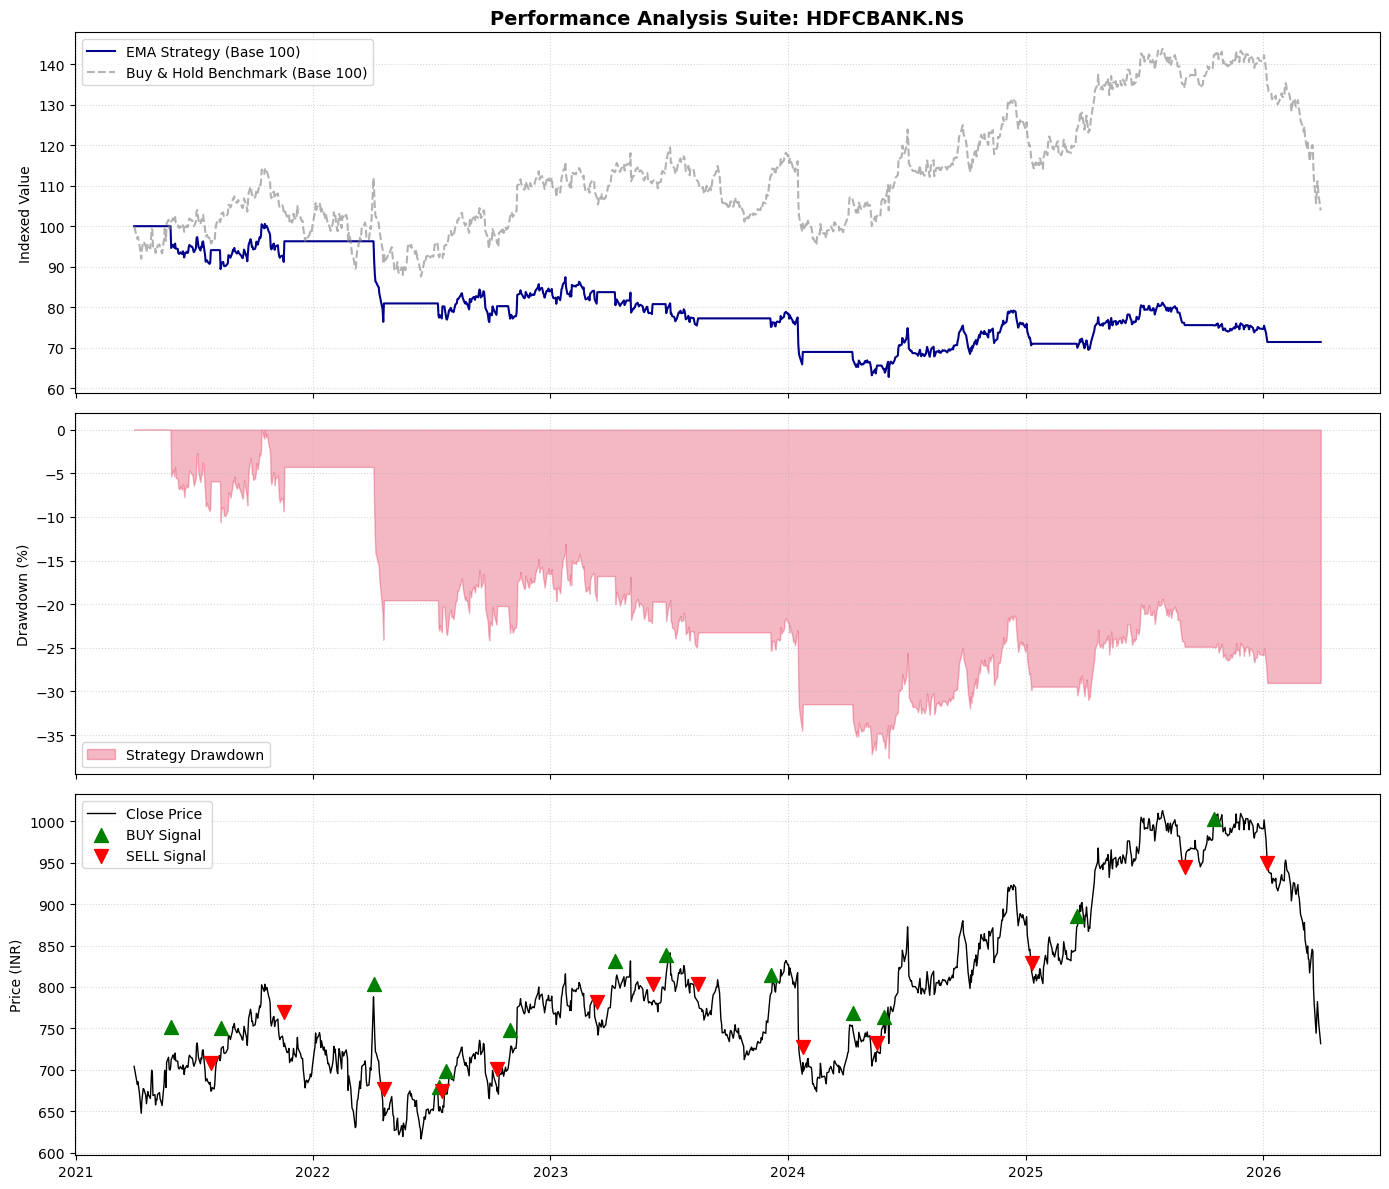


=== BONUS SENSITIVITY PROFILE MATRIX FOR HDFCBANK.NS ===
    Windows   CAGR Sharpe Ratio Max Drawdown
EMA (10/30) -2.98%       -0.062      -32.01%
EMA (20/50) -6.65%       -0.321      -37.63%
EMA (15/45) -5.49%       -0.245      -39.01%

 PROCESSING TRADING SYSTEM BACKTEST FOR TICKER: ONGC.NS 

[SIDE-BY-SIDE PERFORMANCE METRICS FOR ONGC.NS]
      Metric ONGC.NS Strategy ONGC.NS B&H
        CAGR           20.92%      30.79%
Sharpe Ratio            0.625       1.022
Max Drawdown          -28.28%     -35.30%
    Win Rate           63.64%     100.00%

[REALIZED SYSTEM TRADE LOG FOR ONGC.NS]
      Date Action  Price   Shares  Cost Deducted  Portfolio Value
2021-05-04    BUY 109.65 911.0807         100.00         99900.00
2021-07-30   SELL 115.30 911.0807         105.05        104942.56
2021-08-05    BUY 116.85 897.1983         104.94        104837.62
2021-08-10   SELL 114.85 897.1983         103.04        102940.18
2021-09-02    BUY 118.65 866.7277         102.94        102837.24
2021-12-2

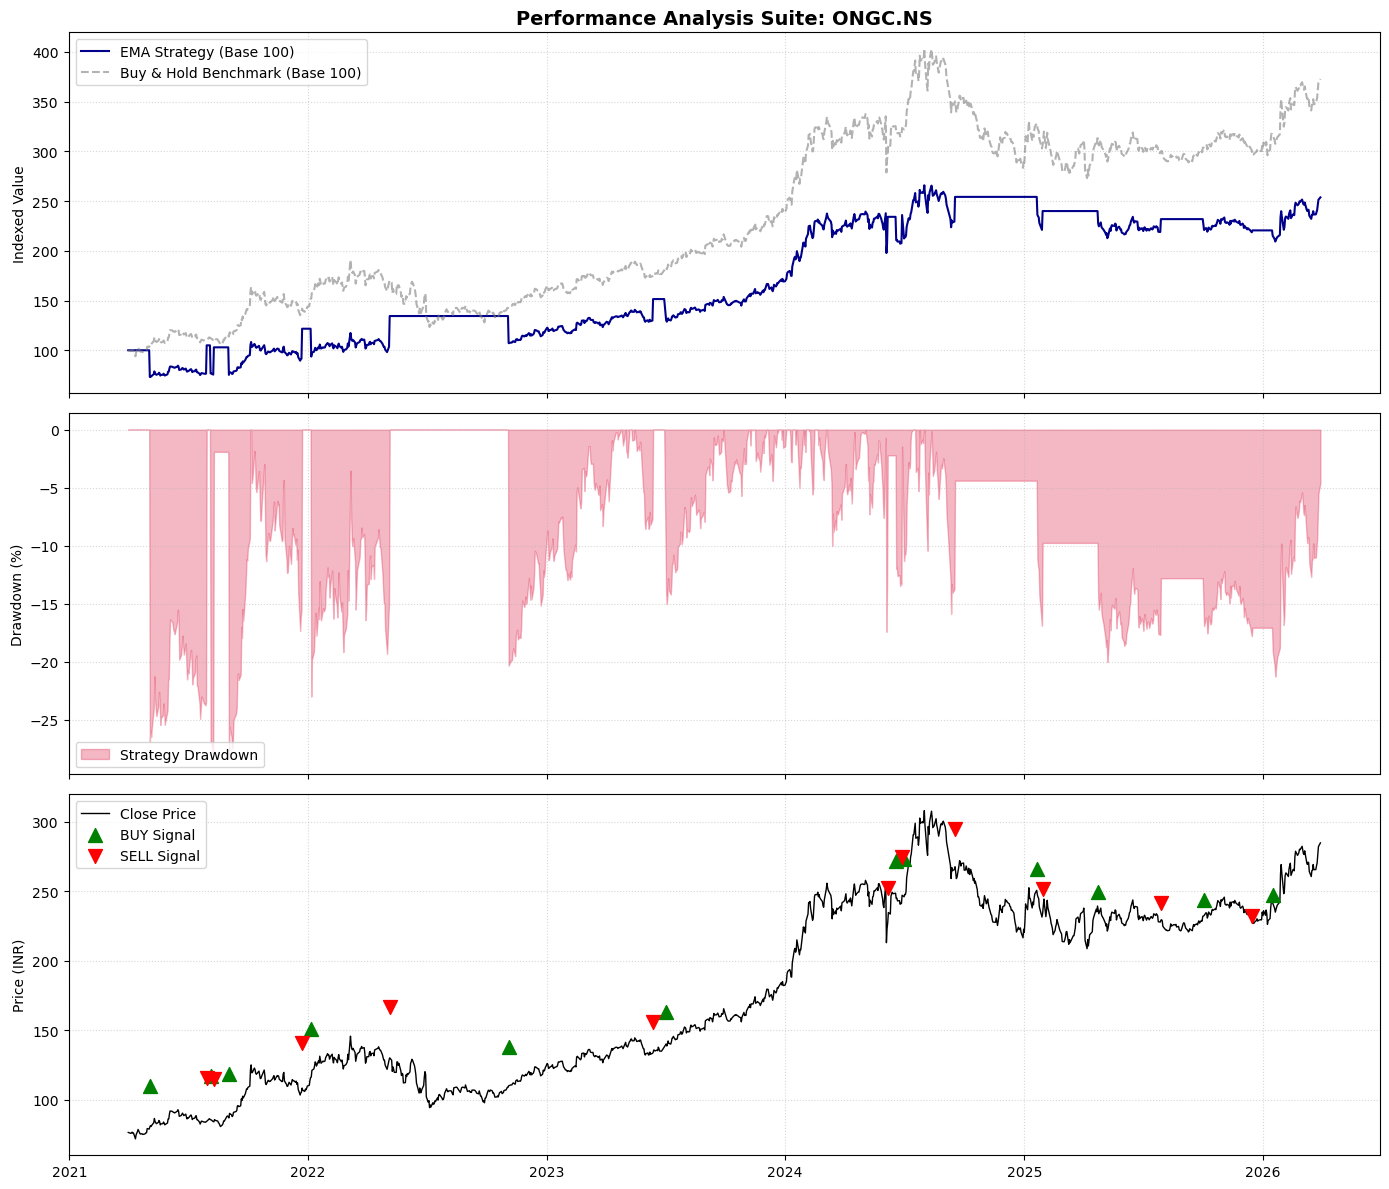


=== BONUS SENSITIVITY PROFILE MATRIX FOR ONGC.NS ===
    Windows   CAGR Sharpe Ratio Max Drawdown
EMA (10/30) 17.27%        0.560      -30.06%
EMA (20/50) 20.92%        0.625      -28.28%
EMA (15/45) 14.34%        0.515      -33.37%


In [17]:
# Main execution block
for ticker in target_stocks:
    print(f"\n" + "="*70)
    print(f" PROCESSING TRADING SYSTEM BACKTEST FOR TICKER: {ticker} ")
    print("="*70)
    
    # 1. Run backtest engine
    strat_df, logs_df = execute_ema_backtest(ticker, stock_data_dict[ticker])
    
    # 2. Display the performance comparison table
    performance_table = compute_performance_table(ticker, strat_df, logs_df)
    print(f"\n[SIDE-BY-SIDE PERFORMANCE METRICS FOR {ticker}]")
    print(performance_table.to_string(index=False))
    
    # 3. Print the completed trade log DataFrame
    print(f"\n[REALIZED SYSTEM TRADE LOG FOR {ticker}]")
    if not logs_df.empty:
        print(logs_df.to_string(index=False))
    else:
        print("No crossover trades occurred for this asset during the timeline.")
        
    # 4. Generate visual chart suite
    render_backtest_charts(ticker, strat_df, logs_df)
    
    # 5. Run sensitivity analytics
    execute_sensitivity_test(ticker, stock_data_dict[ticker])